# OSSE: North American Monsoon Convection

An observing system simulation experiment (OSSE) evaluates how well an observing system, real or planned, would observe a phenomenon, by sampling a high-resolution model simulation (the *nature run*) as the system would. This example is an OSSE of **convection during the North American Monsoon**. The nature run is the 7-km [GEOS-5 Nature Run (G5NR)](https://gmao.gsfc.nasa.gov/global_mesoscale/7km-G5NR/). The *features* of interest are patches of very cold cloud tops over the American Southwest. The observing systems are the atmospheric sounders on the current NOAA/NASA polar-orbiting satellites ([ATMS](ValidateImagerATMS.ipynb) and [CrIS](ValidateImagerCrIS.ipynb)) and two notional future sounders with finer resolution.

The experiment asks two questions about each feature:

1. **Is it observed?** Does a sounder's swath cover the feature, as in the ground-track analyses of earlier TAT-C studies?
2. **Is it resolved?** Is the part of the feature that is observed at least a few resolution elements (footprints or the spacing between them) across? The footprint of a cross-track scanner grows from its nadir value toward the swath edge, so this depends on where in the swath the feature falls.

The steps are:

1. configure the scenario and the nature run (G5NR);
2. define the features (contiguous cold cloud tops) in each 30-minute frame of the nature run;
3. define the sensors (swath parameters fitted to real data in the validation notebooks, and horizontal resolution);
4. compute the ground tracks (swaths) of the satellites over the study region with TAT-C;
5. determine whether each feature is observed and resolved by each sensor;
6. generate a visualization and statistics; and
7. trade the design of the constellation: the number of satellites, their orbit planes, and their sensors.

The example is designed to run in a few minutes, and the constellation trade in a few more (after a one-time download of two weeks of the nature run). It requires the optional dependencies for OSSE examples (`pip install tatc[osse]`).

## Configure the Scenario

The study region is the American Southwest (31-38 N, 115-103 W: Arizona, New Mexico, and neighboring states), the core of the North American Monsoon, whose rains arrive between mid-June and mid-September. The scenario covers two days of the season at the Nature Run's 30-minute time-averaging interval, and is easily extended to the whole season by changing `start` and `duration` (the downloaded data and the computation scale linearly).

The Nature Run covers 15 May 2005 to 16 June 2007 and does not correspond to any real year, so the satellite orbits (those of 16 July 2026, from operational element sets) are paired with the nature run on the same calendar date of its first year. This is appropriate because the orbits are sun-synchronous, so their local solar times of observation do not depend on the date, and the Nature Run represents the diurnal cycle of the season.

In [1]:
from datetime import datetime, timedelta, timezone
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import box

DATA_DIR = Path("data") / "osse"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# study region: the American Southwest, the core of the North American Monsoon
domain = box(-115, 31, -103, 38)
# the simulated orbits (a mid-season date) and the nature run (the same calendar date in the Nature Run's first year)
start = datetime(2026, 7, 16, tzinfo=timezone.utc)
nature_start = start.replace(year=2005)
duration = timedelta(days=2)
frame_duration = timedelta(minutes=30)  # the Nature Run's time-averaging interval
n_frames = int(duration / frame_duration)

## Configure the Nature Run

The G5NR is a two-year global simulation by NASA's Global Modeling and Assimilation Office (GMAO) at a 7-km horizontal resolution, made for OSSEs (Gelaro et al., 2015). NASA serves it by OPeNDAP, which streams only the subset requested. This example uses the single-level, 30-minute time-averaged physics diagnostics at 0.0625 degrees (about 7 km), and reads the upwelling longwave flux at the top of the atmosphere (`lwtup`), a proxy for cloud-top temperature, and the convective precipitation rate (`preccon`). All frames for the study region are requested at once and saved in a local `data/osse` directory, so later runs are fast.

In [2]:
import xarray as xr

G5NR_URL = "https://opendap.nccs.nasa.gov/dods/OSSE/G5NR/Ganymed/7km/0.0625_deg/tavg/tavg30mn_2d_met3_Nx"
GRID_SIZE = 0.0625  # deg


def load_nature(duration):
    """The Nature Run over the study region for a duration from nature_start, downloaded once to DATA_DIR."""
    nature_file = DATA_DIR / f"g5nr_{nature_start:%Y%m%d}_{duration.days}d.nc"
    if not nature_file.exists():
        # one request for all frames of the study region (a few minutes per two weeks)
        minx, miny, maxx, maxy = domain.bounds
        with xr.open_dataset(G5NR_URL, decode_times=True) as remote:
            remote[["lwtup", "preccon"]].sel(
                time=slice(nature_start.replace(tzinfo=None), (nature_start + duration).replace(tzinfo=None)),
                lon=slice(minx, maxx),
                lat=slice(miny, maxy),
            ).load().to_netcdf(nature_file)
    nature = xr.load_dataset(nature_file)
    assert nature.sizes["time"] == int(duration / frame_duration)
    # each time stamp is the middle of its 30-minute averaging interval
    assert (nature.time.values[0] - np.datetime64(nature_start.replace(tzinfo=None))) == np.timedelta64(15, "m")
    return nature


nature = load_nature(duration)
nature

<xarray.Dataset> Size: 17MB
Dimensions:  (time: 96, lat: 113, lon: 193)
Coordinates:
  * time     (time) datetime64[ns] 768B 2005-07-16T00:15:00 ... 2005-07-17T23...
  * lat      (lat) float64 904B 31.0 31.06 31.12 31.19 ... 37.88 37.94 38.0
  * lon      (lon) float64 2kB -115.0 -114.9 -114.9 ... -103.1 -103.1 -103.0
Data variables:
    lwtup    (time, lat, lon) float32 8MB 314.9 315.9 314.4 ... 301.4 301.4
    preccon  (time, lat, lon) float32 8MB 0.0 0.0 0.0 ... 0.0 1.764e-08
Attributes:
    title:                2d,30-Minute,Time-Averaged,Single-Level,Full Resolu...
    Conventions:          COARDS\nGrADS
    dataType:             Grid
    history:              Mon Sep 28 14:37:35 EDT 2026 : imported by GrADS Da...
    extra_das_attribute:  This is an example of metadata added using a supple...

## Define the Environmental Features

Features are contiguous patches of grid cells whose upwelling longwave flux is below that of a 220 K blackbody (`5.67037e-8 * 220**4` W m-2, about 133 W m-2), that is, whose clouds are very cold and therefore very high, as in deep convection. Each patch in each frame is a feature. (A convective system that persists for several frames is counted in each, and a feature is a snapshot of it.) Patches smaller than the Nature Run's effective resolution are discarded, because no sensor can be evaluated against features that the Nature Run does not credibly represent. Like other models, the G5NR damps its smallest scales: its evaluation finds that its true resolution "should be considered as several times coarser than its grid spacing of 7 km" but gives no single value (Gelaro et al., 2015, Section 2.2). Features are therefore kept if their size is at least `EFFECTIVE_RESOLUTION_KM`, four grid spacings (28 km) by default.

For each feature, the notebook records its area, the diameter of a circle of the same area (its size, used throughout), the area-weighted centroid, its coldest flux and highest convective precipitation rate, the total convective precipitation, and the solar hour at the centroid (the Sun's hour angle plus 12 hours, which is 12 at local solar noon).

In [3]:
import scipy.ndimage as ndi
from skyfield.api import wgs84

from tatc.constants import EARTH_MEAN_RADIUS, de421, timescale

THRESHOLD = 5.67037e-8 * 220**4  # W m-2, the upwelling longwave flux of a 220 K blackbody
EFFECTIVE_RESOLUTION_KM = 4 * 7  # km, several grid spacings (Gelaro et al., 2015); smaller features are not resolved


def find_features(nature):
    """The features (contiguous cold cloud tops at least EFFECTIVE_RESOLUTION_KM in size) in each frame of the nature run."""
    lon, lat = nature.lon.values, nature.lat.values
    lon2d, lat2d = np.meshgrid(lon, lat)
    cell_area = (EARTH_MEAN_RADIUS * np.radians(GRID_SIZE)) ** 2 * np.cos(np.radians(lat2d))  # m^2

    records, polygons = [], []
    for frame in range(nature.sizes["time"]):
        lwtup = nature["lwtup"].isel(time=frame).values
        preccon = nature["preccon"].isel(time=frame).values
        labels, n_labels = ndi.label(lwtup < THRESHOLD)  # contiguous cells colder than the threshold
        if n_labels == 0:
            continue
        ids = np.arange(1, n_labels + 1)
        area = ndi.sum(cell_area, labels, ids)
        n_cells = ndi.sum(np.ones_like(lwtup), labels, ids).astype(int)
        # polygons are the unions of the cells, which are centered on the grid points
        j, i = np.nonzero(labels)
        order = np.argsort(labels[j, i], kind="stable")
        j, i = j[order], i[order]
        cells = shapely.box(
            lon[i] - GRID_SIZE / 2, lat[j] - GRID_SIZE / 2, lon[i] + GRID_SIZE / 2, lat[j] + GRID_SIZE / 2
        )
        for k, cluster in enumerate(np.split(cells, np.cumsum(n_cells)[:-1])):
            records.append(
                {
                    "frame": frame,
                    "n_cells": n_cells[k],
                    "area_km2": area[k] / 1e6,
                    "lon": ndi.sum(cell_area * lon2d, labels, ids[k]) / area[k],
                    "lat": ndi.sum(cell_area * lat2d, labels, ids[k]) / area[k],
                    "min_lwtup": ndi.minimum(lwtup, labels, ids[k]),
                    "max_preccon": ndi.maximum(preccon, labels, ids[k]),
                    "tot_preccon": ndi.sum(preccon * cell_area, labels, ids[k]),
                }
            )
            polygons.append(shapely.union_all(cluster))

    features = gpd.GeoDataFrame(records, geometry=polygons, crs="EPSG:4326")
    features["diameter_km"] = np.sqrt(4 * features.area_km2 / np.pi)  # of a circle of equal area
    features = features[features.diameter_km >= EFFECTIVE_RESOLUTION_KM].reset_index(drop=True)
    features["time"] = start + features.frame * frame_duration
    # solar hour at the feature (hour angle of the Sun plus 12 hours) at the middle of the frame, in the Nature Run's year
    solar_time = timescale.from_datetimes([nature_start + (frame + 0.5) * frame_duration for frame in features.frame])
    features["solar_hour"] = (
        de421["earth"] + wgs84.latlon(features.lat.values, features.lon.values)
    ).at(solar_time).observe(de421["sun"]).apparent().hadec()[0].hours + 12
    return features


features = find_features(nature)
features[["time", "n_cells", "area_km2", "diameter_km", "lon", "lat", "min_lwtup", "max_preccon", "solar_hour"]].describe().round(2)

,n_cells,area_km2,diameter_km,lon,lat,min_lwtup,max_preccon,solar_hour
count,285.00,285.00,285.00,285.00,285.00,285.00,285.0,285.00
mean,66.66,2631.64,53.48,-109.70,34.99,125.31,0.0,15.68
std,61.26,2415.42,22.18,1.91,2.10,3.04,0.0,6.12
min,15.00,616.22,28.01,-113.09,31.05,115.96,0.0,0.20
25%,27.00,1058.41,36.71,-111.30,33.13,123.18,0.0,13.13
50%,44.00,1722.97,46.84,-110.07,35.26,125.71,0.0,17.02
75%,86.00,3472.57,66.49,-108.12,37.00,127.62,0.0,20.37
max,352.00,14112.45,134.05,-105.21,37.95,131.43,0.0,23.92


## Define the Sensors

**Platforms.** The current constellation of sounders is Suomi NPP, NOAA-20, and NOAA-21, three satellites in a sun-synchronous orbit with an ascending node of about 13:30 local time. Each carries both the Advanced Technology Microwave Sounder (ATMS) and the Cross-track Infrared Sounder (CrIS).

**Swaths.** Each instrument is a rectangular `PointedInstrument` whose cross-track field of view spans its scan positions, using the scan parameters fitted to NOAA-20 data in the validation notebooks ([ATMS](ValidateImagerATMS.ipynb) and [CrIS](ValidateImagerCrIS.ipynb)): the effective spacing between scan positions and the roll angle, and a scan perpendicular to the inertial velocity (`VelocityFrame.INERTIAL`) rather than to the ground track. The along-track field of view is tailored to the 30 s time step (`compute_along_track_field_of_view`), so that consecutive footprints tile the swath. NOAA-21 and Suomi NPP are assumed identical to NOAA-20.

**Resolution.** Each sensor has a horizontal resolution (the diameter of its footprint at nadir) and a sample spacing (the distance between the centers of neighboring footprints at nadir). A sensor cannot resolve detail finer than either its footprint or its sample spacing, so its *resolution element* is the larger of the two. ATMS oversamples (its 2.2 degree beams overlap at a 1.11 degree spacing), so its footprint limits it. CrIS undersamples slightly (its 0.963 degree views leave gaps at a 1.09 degree pitch), so its sample spacing limits it. The future sensors are assumed to sample in proportion to their footprints, in the same ratio as their heritage counterparts, so a future infrared sounder has as many more views per scan as its finer footprint requires.

| Sensor | Horizontal | Sampling | Basis |
| --- | --- | --- | --- |
| ATMS | 32 km | 16 km | 2.2 degree beam of the temperature sounding channels and 1.112 degree spacing of scan positions at about 830 km, confirmed by the [ATMS validation](ValidateImagerATMS.ipynb) |
| CrIS | 14 km | 16 km | 0.963 degree field of view and 1.092 degree pitch of the 3 x 3 array of views at about 830 km, confirmed by the [CrIS validation](ValidateImagerCrIS.ipynb) |
| Future MW | 10 km | 5 km | target of a future microwave sounder, sampled as ATMS |
| Future IR | 3 km | 3.4 km | target of a future infrared sounder, sampled as CrIS |

To isolate the effect of resolution, the future sensors are assumed to fly on the same platforms with the same scans (swaths) as their heritage counterparts: the future microwave sounder shares the ATMS swath and the future infrared sounder shares the CrIS swath.

In [4]:
from tatc.schemas import GeneralPerturbationsOrbit, PointedInstrument, Satellite
from tatc.utils import VelocityFrame, compute_along_track_field_of_view

# element sets (epoch 2026-07-16 00:00 UTC) from the JPSS TLE-AUX archive, as in the validation notebooks
tles = {
    "Suomi NPP": [
        "1 37849U 11061A   26197.00000000  .00000095  00000-0  44942-4 0  2449",
        "2 37849  98.7951 137.6822 0001041 201.8158  13.6707 14.19522526762525",
    ],
    "NOAA-20": [
        "1 43013U 17073A   26197.00000000  .00000069  00000-0  32863-4 0  1908",
        "2 43013  98.7768 136.2093 0001592 131.9807  15.3167 14.19516563448569",
    ],
    "NOAA-21": [
        "1 54234U 22150A   26197.00000000  .00000063  00000-0  30079-4 0  9591",
        "2 54234  98.7055 135.3072 0002920 108.6153 233.8084 14.19541053190632",
    ],
}
orbits = {name: GeneralPerturbationsOrbit.from_tle(tle) for name, tle in tles.items()}

# scan parameters fitted to NOAA-20 data in the ATMS and CrIS validation notebooks: the number of scan positions,
# their spacing (deg), and the roll angle (deg, positive to the left); both scan perpendicular to the inertial velocity
scans = {
    "ATMS": {"positions": 96, "spacing": 1.112, "roll": 0.04},
    "CrIS": {"positions": 30, "spacing": 3.334, "roll": -0.093},
}
TIME_STEP = 30  # s, of the ground track


def swath_instrument(name):
    """A rectangular view spanning the scan positions, tailored to the time step (as validated for ATMS and CrIS)."""
    scan = scans[name]
    field_of_regard = (scan["positions"] - 1) * scan["spacing"]
    return PointedInstrument(
        name=name,
        field_of_regard=field_of_regard,
        cross_track_field_of_view=field_of_regard,
        along_track_field_of_view=compute_along_track_field_of_view(
            orbits["NOAA-20"].get_mean_altitude(), TIME_STEP, orbits["NOAA-20"].get_inclination()
        ),
        roll_angle=scan["roll"],
        is_rectangular=True,
        velocity_frame=VelocityFrame.INERTIAL,
    )


satellites = [
    Satellite(name=name, orbit=orbit, instruments=[swath_instrument("ATMS"), swath_instrument("CrIS")])
    for name, orbit in orbits.items()
]

REFERENCE_RANGE_KM = 830  # nominal slant range at nadir (altitude), at which the nominal resolutions apply
# angular spacing (deg) of the samples of each scan, fitted to NOAA-20 data in the validation notebooks: the ATMS scan
# positions and the pitch of the CrIS 3 x 3 array of views
SAMPLING_DEG = {"ATMS": scans["ATMS"]["spacing"], "CrIS": 1.092}
# sensors: the scan (swath) they share, and their horizontal resolution at nadir (km)
sensors = pd.DataFrame(
    [
        {"sensor": "ATMS", "swath": "ATMS", "horizontal_km": 32},
        {"sensor": "CrIS", "swath": "CrIS", "horizontal_km": 14},
        {"sensor": "Future MW", "swath": "ATMS", "horizontal_km": 10},
        {"sensor": "Future IR", "swath": "CrIS", "horizontal_km": 3},
    ]
).set_index("sensor")
# sample spacing at nadir (km): that of the heritage sensor, scaled for the future sensors in proportion to their footprint
heritage_km = sensors.horizontal_km[sensors.swath].values
sensors["sampling_km"] = REFERENCE_RANGE_KM * np.radians(sensors.swath.map(SAMPLING_DEG)) * sensors.horizontal_km / heritage_km
sensors.round(1)

,swath,horizontal_km,sampling_km
sensor,,,
ATMS,ATMS,32,16.1
CrIS,CrIS,14,15.8
Future MW,ATMS,10,5.0
Future IR,CrIS,3,3.4


## Compute the Ground Tracks

`collect_ground_track` returns the footprint of each instrument at each time step, clipped to the study region (the `mask`), which are tabulated per frame and combined (`swaths`) to find the area each swath covers in each frame. Each satellite crosses the region on a few passes per day, so this is quick.

In [5]:
from tatc.analysis import collect_ground_track


def collect_tracks(satellites, duration):
    """The footprint of every instrument of the satellites at each time step over a duration from start, clipped to the
    study region, with its frame."""
    times = [start + timedelta(seconds=TIME_STEP * (i + 0.5)) for i in range(int(duration.total_seconds() // TIME_STEP))]
    tracks = collect_ground_track(satellites, times, instrument_index=None, mask=domain)
    tracks = tracks[tracks.valid_obs].reset_index(drop=True)
    tracks["geometry"] = shapely.force_2d(tracks.geometry.values)
    tracks["frame"] = ((tracks.time - start) // frame_duration).astype(int)
    return tracks


tracks = collect_tracks(satellites, duration)
# the area swept by each swath (ATMS or CrIS) in each frame
swaths = tracks.groupby(["frame", "instrument"]).geometry.agg(shapely.union_all)
tracks.groupby(["satellite", "instrument"]).agg(footprints=("time", "size"), first=("time", "min"), last=("time", "max"))

footprints                     first  \
satellite instrument                                         
NOAA-20   ATMS                48 2026-07-16 08:26:15+00:00   
          CrIS                46 2026-07-16 08:26:15+00:00   
NOAA-21   ATMS                25 2026-07-16 09:12:15+00:00   
          CrIS                23 2026-07-16 09:12:15+00:00   
Suomi NPP ATMS                40 2026-07-16 08:06:45+00:00   
          CrIS                33 2026-07-16 08:07:15+00:00   

                                          last  
satellite instrument                            
NOAA-20   ATMS       2026-07-17 21:09:45+00:00  
          CrIS       2026-07-17 21:09:45+00:00  
NOAA-21   ATMS       2026-07-17 20:15:15+00:00  
          CrIS       2026-07-17 20:15:15+00:00  
Suomi NPP ATMS       2026-07-17 20:50:45+00:00  
          CrIS       2026-07-17 20:50:45+00:00

## Compute Observability and Resolution

A feature is **observed** by a swath if the swath footprint of some time step in its frame overlaps it. A **look** is one satellite's view of a feature in its frame. It covers the part of the feature inside that satellite's swath, which is only part of it if the feature straddles the swath edge, and the size of this viewed part (the diameter of a circle of the same area) is what the sensor must resolve.

For each look, the satellite's slant range and zenith angle at the centroid of the viewed part follow from the satellite position at the time of the footprint that covers most of it (TAT-C's orbit propagation), and give the size of the sensor's resolution element there: the element's angular size (the larger of the footprint and the sample spacing at nadir) times the slant range along track, and longer by the secant of the zenith angle across track. The validation notebooks confirmed this geometry against the reported viewing geometry of real data. Two measures of the size of the element are offered (`ELEMENT_AXIS`):

* `"equivalent"` (the default): the diameter of a circle of the same area, the geometric mean of the along-track and cross-track sizes; and
* `"cross-track"`: the cross-track size, a stricter measure, which is up to about 2.3 times the along-track size at the swath edges of ATMS and 1.9 times at those of CrIS.

If a feature has several looks, the best (the one whose viewed part spans the most resolution elements) is used.

A feature is **resolved** if its viewed part spans at least `RESOLUTION_FACTOR` resolution elements. The default of two is a heuristic (a feature must span at least a couple of independent samples to be distinguished from its surroundings), and the sensitivity to it and to the measure of the element is shown below.

In [6]:
from pyproj import Transformer
from skyfield.framelib import itrs

RESOLUTION_FACTOR = 2  # a feature is resolved if its viewed part spans at least this many resolution elements
ELEMENT_AXIS = "equivalent"  # the size of a resolution element: "equivalent" (diameter of equal area) or "cross-track"
AXES = ["equivalent", "cross-track"]

TO_ECEF = Transformer.from_crs("EPSG:4979", "EPSG:4978", always_xy=True)


def up(lon, lat):
    """Geodetic up unit vector, stacked on the last axis."""
    lon, lat = np.radians(lon), np.radians(lat)
    return np.stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)], axis=-1)


def element_size(slant_range, zenith, nadir_km, axis):
    """Size (km) of a resolution element of size nadir_km at nadir: its angular size times the slant range (m) along
    track, and longer by the secant of the zenith angle (deg) cross track. The size is the diameter of a circle of the
    same area (axis="equivalent", the geometric mean of the two) or the cross-track size (axis="cross-track")."""
    along = slant_range / 1e3 * nadir_km / REFERENCE_RANGE_KM
    cross = along / np.cos(np.radians(zenith))
    return cross if axis == "cross-track" else np.sqrt(along * cross)


def collect_looks(tracks, features, orbits):
    """The looks at the features from the tracks: the part of each feature inside a satellite's swath in its frame, at
    the time of the footprint that covers most of it, with the slant range and zenith angle at its centroid."""
    # pieces: the parts of each feature inside each footprint (of a satellite's instrument, at a time) in the same frame
    pieces = gpd.sjoin(
        features[["frame", "geometry"]],
        tracks[["frame", "satellite", "instrument", "time", "geometry"]].rename(columns={"frame": "frame_track"}),
        predicate="intersects",
    )
    pieces = pieces[pieces.frame == pieces.frame_track].rename_axis("feature").reset_index()
    pieces["geometry"] = shapely.intersection(pieces.geometry.values, tracks.geometry.values[pieces.index_right])
    pieces["piece_area"] = shapely.area(pieces.geometry.values)

    # looks: the part of each feature inside a satellite's swath, at the time of the footprint that covers most of it
    looks = (
        pieces.sort_values("piece_area", ascending=False)
        .groupby(["feature", "satellite", "instrument"])
        .agg(time=("time", "first"), geometry=("geometry", shapely.union_all))
        .reset_index()
    )
    looks["viewed_fraction"] = np.minimum(
        1, shapely.area(looks.geometry.values) / shapely.area(features.geometry.values[looks.feature])
    )
    looks["viewed_km"] = np.sqrt(4 * looks.viewed_fraction * features.area_km2.values[looks.feature] / np.pi)
    centroids = shapely.centroid(looks.geometry.values)
    looks["lon"], looks["lat"] = shapely.get_x(centroids), shapely.get_y(centroids)

    # the viewing geometry (slant range and zenith angle) from the satellite position at the time of the footprint
    looks["range_m"], looks["zenith"] = np.nan, np.nan
    for name, group in looks.groupby("satellite"):
        sat_xyz = np.array(orbits[name].to_gp_orbit().get_orbit_track(list(group.time)).frame_xyz(itrs).m).T
        target = np.stack(TO_ECEF.transform(group.lon.values, group.lat.values, np.zeros(len(group))), axis=-1)
        line_of_sight = sat_xyz - target
        looks.loc[group.index, "range_m"] = np.linalg.norm(line_of_sight, axis=-1)
        looks.loc[group.index, "zenith"] = np.degrees(
            np.arccos(
                np.sum(line_of_sight * up(group.lon.values, group.lat.values), axis=-1)
                / np.linalg.norm(line_of_sight, axis=-1)
            )
        )
    return looks


def assess(looks, features):
    """Whether each sensor observes and resolves each feature, from its best look."""
    results = []
    for sensor, row in sensors.iterrows():
        sensor_looks = looks[looks.instrument == row.swath].copy()
        # the resolution element at nadir is the larger of the footprint and the sample spacing
        nadir_km = max(row.horizontal_km, row.sampling_km)
        for axis in AXES:
            element_km = element_size(sensor_looks.range_m, sensor_looks.zenith, nadir_km, axis)
            sensor_looks[f"elements ({axis})"] = sensor_looks.viewed_km / element_km
            if axis == ELEMENT_AXIS:
                sensor_looks["element_km"] = element_km
        # the best look at each feature: the one whose viewed part spans the most resolution elements
        best = sensor_looks.loc[sensor_looks.groupby("feature")[f"elements ({ELEMENT_AXIS})"].idxmax()].set_index("feature")
        result = features[["frame", "diameter_km", "area_km2", "tot_preccon", "solar_hour"]].copy()
        result["sensor"] = sensor
        result["looks"] = sensor_looks.groupby("feature").size().reindex(result.index, fill_value=0)
        result["observed"] = result.looks > 0
        result = result.join(best[["satellite", "zenith", "viewed_fraction", "viewed_km", "element_km"]])
        for axis in AXES:
            result[f"elements ({axis})"] = sensor_looks.groupby("feature")[f"elements ({axis})"].max()
        result["resolved"] = result[f"elements ({ELEMENT_AXIS})"] >= RESOLUTION_FACTOR
        results.append(result)
    return pd.concat(results).reset_index().rename(columns={"index": "feature"})


looks = collect_looks(tracks, features, orbits)
results = assess(looks, features)
results.groupby("sensor")[["observed", "resolved"]].sum().join(sensors).loc[sensors.index].round(1)

,observed,resolved,swath,horizontal_km,sampling_km
sensor,,,,,
ATMS,41,2,ATMS,32,16.1
CrIS,35,18,CrIS,14,15.8
Future MW,41,33,ATMS,10,5.0
Future IR,35,35,CrIS,3,3.4


## Generate a Visualization

The figure shows one frame, the one with the most features whose status differs between the sensors. Features are colored by whether each sensor resolves them (blue), observes but does not resolve them (orange), or does not observe them (faded, outside the swath). The underlying image is the nature run's upwelling longwave flux, whose dark areas are cold cloud tops.

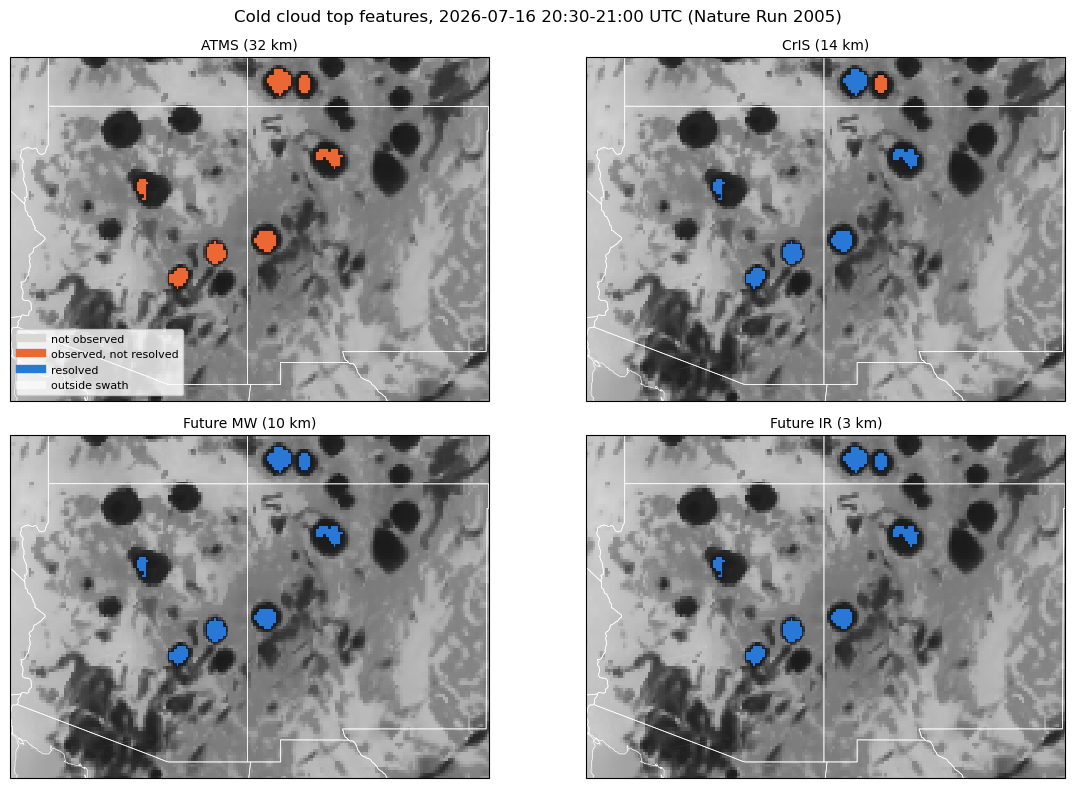

In [7]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# the frame with the most features whose status (not observed, observed, or resolved) differs between the sensors
status = results.observed.astype(int) + results.resolved.astype(int)
example = (status.groupby([results.frame, results.feature]).nunique() > 1).groupby("frame").sum().idxmax()
example_time = start + example * frame_duration
STATUS = {"not observed": "#d9d8d3", "observed, not resolved": "#eb6834", "resolved": "#2a78d6"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, sensor in zip(axes.ravel(), sensors.index):
    background = nature["lwtup"].isel(time=example)
    ax.pcolormesh(background.lon, background.lat, background, cmap="Greys_r", vmin=100, vmax=450, shading="auto", transform=ccrs.PlateCarree())
    members = results[(results.sensor == sensor) & (results.frame == example)]
    status = np.where(members.resolved, "resolved", np.where(members.observed, "observed, not resolved", "not observed"))
    for label, color in STATUS.items():
        selected = features.loc[members.feature[status == label]]
        if len(selected):
            selected.plot(ax=ax, facecolor=color, edgecolor="black", linewidth=0.4, transform=ccrs.PlateCarree())
    # fade the part of the study region outside the swath
    swath = swaths.get((example, sensors.loc[sensor, "swath"]))
    outside = domain if swath is None else domain.difference(swath)
    ax.add_geometries([outside], crs=ccrs.PlateCarree(), facecolor="white", edgecolor="none", alpha=0.6)
    ax.add_feature(cfeature.STATES, edgecolor="white", linewidth=0.5)
    ax.set_extent([domain.bounds[0], domain.bounds[2], domain.bounds[1], domain.bounds[3]])
    ax.set_title(f"{sensor} ({sensors.loc[sensor, 'horizontal_km']} km)", fontsize=10)
for label, color in STATUS.items():
    axes[0, 0].plot([], [], color=color, lw=6, label=label)
axes[0, 0].plot([], [], color="#ffffff", lw=6, alpha=0.6, label="outside swath")
axes[0, 0].legend(loc="lower left", fontsize=8, frameon=True)
fig.suptitle(f"Cold cloud top features, {example_time:%Y-%m-%d %H:%M}-{example_time + frame_duration:%H:%M} UTC (Nature Run {nature_start:%Y})")
fig.tight_layout()
plt.show()

## Generate Statistics

The table gives, for each sensor, the share of all features that are observed and resolved, the share of the total feature area and of the total convective precipitation that lies in resolved features, and the median resolution element at the observed features. The shares of area and precipitation count the whole of each resolved feature, even if only part of it is viewed.

In [8]:
total = {"features": len(features), "area": features.area_km2.sum(), "precipitation": features.tot_preccon.sum()}
summary = results.groupby("sensor").apply(
    lambda r: pd.Series(
        {
            "observed (% of features)": 100 * r.observed.mean(),
            "resolved (% of features)": 100 * r.resolved.mean(),
            "resolved (% of area)": 100 * r.area_km2[r.resolved].sum() / total["area"],
            "resolved (% of precipitation)": 100 * r.tot_preccon[r.resolved].sum() / total["precipitation"],
            "median resolution element of observed (km)": r.element_km[r.observed].median(),
        }
    ),
    include_groups=False,
).loc[sensors.index]
summary.round(1)

,observed (% of features),resolved (% of features),resolved (% of area),resolved (% of precipitation),median resolution element of observed (km)
sensor,,,,,
ATMS,14.4,0.7,1.5,2.8,49.5
CrIS,12.3,6.3,7.0,14.8,21.8
Future MW,14.4,11.6,11.7,23.1,15.5
Future IR,12.3,12.3,10.8,22.3,4.7


Over the two days, the study region has 285 features at least 28 km in size (the median is 47 km, and three quarters are smaller than 66 km). The sounders observe 12 to 14% of them (35 in the CrIS swath and 41 in the wider ATMS swath), because the three satellites are all in the same orbit plane and cross the region within about an hour (near 13:30 local time) on their afternoon passes and again about 12 hours later (near 01:30), whereas the features concentrate in the afternoon and evening (see the solar hour below); finer resolution does not change this, because the swaths are the same. Only a few observed features straddle a swath edge (3 to 5 at their best look), so counting the viewed part rather than the centroid changes little here: requiring the centroid to be in the swath would observe one fewer feature in each swath.

Among the features observed, resolution matters a great deal: with a criterion of two resolution elements, ATMS resolves almost none of them (2 of 41), because the median resolution element at the observed features (50 km, larger than its 32 km nadir footprint because features are observed away from nadir) exceeds the 47 km median feature. CrIS resolves half (18 of 35), with a median element of 22 km set by its sample spacing rather than its footprint. A future microwave sounder resolves four fifths (33 of 41), and a future infrared sounder, sampling in proportion to its 3 km footprint, all of them (35 of 35), with a median of about 10 elements across each.

Because the larger features (which are resolved first) are also the wetter ones, the resolved share of convective precipitation is greater than the resolved share of features (15% for CrIS, 23% for a future microwave sounder, and 22% for a future infrared sounder). The future infrared sounder resolves a slightly smaller share of precipitation than the future microwave sounder because the CrIS swath is narrower than the ATMS swath, so it observes fewer features (35 vs. 41): once the resolution is fine enough, observability is limited by the swath. With a single two-day realization, differences of a point or two between the future sensors are within sampling noise.

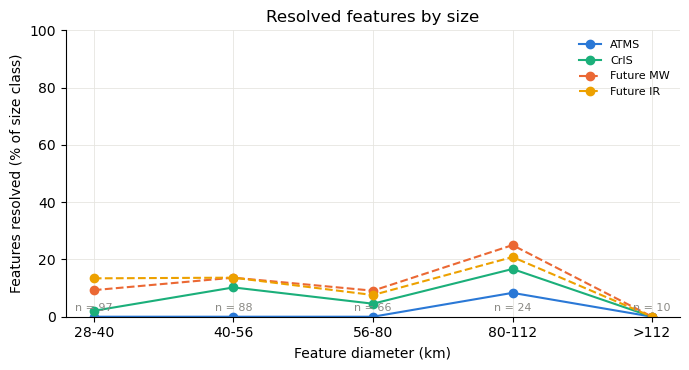

size_class,28-40,40-56,56-80,80-112,>112
sensor,,,,,
ATMS,0.0,0.0,0.0,8.3,0.0
CrIS,2.1,10.2,4.5,16.7,0.0
Future MW,9.3,13.6,9.1,25.0,0.0
Future IR,13.4,13.6,7.6,20.8,0.0


In [9]:
BLUE, ORANGE, AQUA, YELLOW, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984", "#0b0b0b"
SENSOR_COLORS = {"ATMS": BLUE, "Future MW": ORANGE, "CrIS": AQUA, "Future IR": YELLOW}
SENSOR_STYLES = {"ATMS": "-", "Future MW": "--", "CrIS": "-", "Future IR": "--"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})

edges = np.array([EFFECTIVE_RESOLUTION_KM, 40, 56, 80, 112, np.inf])
labels = [f"{EFFECTIVE_RESOLUTION_KM}-40", "40-56", "56-80", "80-112", ">112"]
results["size_class"] = pd.cut(results.diameter_km, edges, labels=labels, right=False)
by_size = results.groupby(["sensor", "size_class"], observed=False).resolved.mean().unstack().loc[sensors.index] * 100
counts = results[results.sensor == "ATMS"].groupby("size_class", observed=False).size()

fig, ax = plt.subplots(figsize=(7, 3.8))
for sensor in sensors.index:
    ax.plot(labels, by_size.loc[sensor], marker="o", color=SENSOR_COLORS[sensor], ls=SENSOR_STYLES[sensor], label=sensor)
ax.set(xlabel="Feature diameter (km)", ylabel="Features resolved (% of size class)", title="Resolved features by size", ylim=(0, 100))
ax.legend(frameon=False, fontsize=8)
for x, n in zip(labels, counts):
    ax.annotate(f"n = {n}", (x, 2), ha="center", fontsize=8, color=GRAY)
fig.tight_layout()
plt.show()
by_size.round(1)

Resolution matters most for the smaller features. The shares are of all features in each size class, so they also reflect how many of them are observed (none of the 10 features larger than 112 km happens to be observed), and those of a future infrared sounder, which resolves every feature it observes, are its observed shares. The sensors differ most for the smallest features (28 to 40 km): a future infrared sounder resolves 13% of them, a future microwave sounder 9%, CrIS 2%, and ATMS none. ATMS resolves only features larger than 80 km (8% of them).

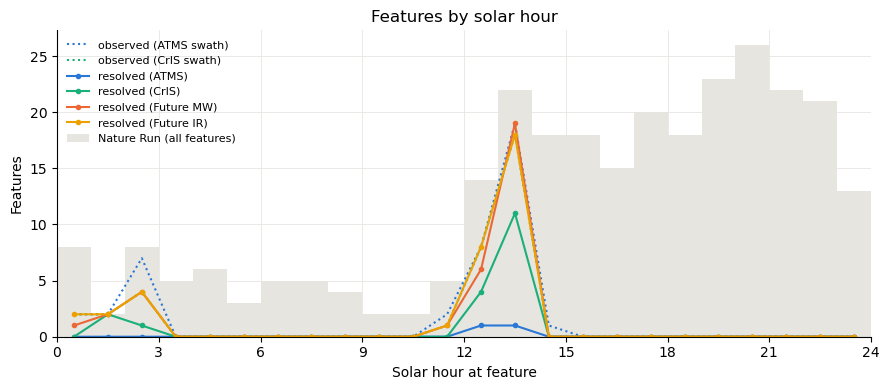

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 25, 1)
nature_hist, _ = np.histogram(features.solar_hour, bins)
ax.bar(bins[:-1] + 0.5, nature_hist, width=1, color="#e6e5e0", label="Nature Run (all features)")
for swath, style, color in [("ATMS", ":", BLUE), ("CrIS", ":", AQUA)]:
    r = results[results.sensor == swath]
    hist, _ = np.histogram(r.solar_hour[r.observed], bins)
    ax.plot(bins[:-1] + 0.5, hist, ls=":", color=color, label=f"observed ({swath} swath)")
for sensor in sensors.index:
    r = results[results.sensor == sensor]
    hist, _ = np.histogram(r.solar_hour[r.resolved], bins)
    ax.plot(bins[:-1] + 0.5, hist, ls="-", marker="o", ms=3, color=SENSOR_COLORS[sensor], label=f"resolved ({sensor})")
ax.set(xlabel="Solar hour at feature", ylabel="Features", title="Features by solar hour", xlim=(0, 24))
ax.set_xticks(range(0, 25, 3))
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

The solar hour of the features shows when the sampling gap arises. Features are most frequent in the late afternoon and evening (about 17 to 21 solar hours), after the satellites' afternoon pass (near 13:30), which samples the developing convection, and well before their next pass (near 01:30), which samples the decaying convection. A constellation with a different distribution of local times (for example, satellites in other orbit planes) would observe more of the features, independently of resolution, as the constellation trade below shows.

In [11]:
# sensitivity to the resolution criterion: the share of features resolved if their viewed part must span at least N
# resolution elements, of either size
sensitivity = pd.DataFrame(
    {
        (axis, f"N = {n}"): results.groupby("sensor")[f"elements ({axis})"].apply(lambda r: 100 * (r >= n).mean())
        for axis in AXES
        for n in (1, 2, 3)
    }
).loc[sensors.index]
sensitivity.round(1)

equivalent             cross-track            
               N = 1 N = 2 N = 3       N = 1 N = 2 N = 3
sensor                                                  
ATMS             6.7   0.7   0.0         5.3   0.7   0.0
CrIS            11.6   6.3   1.8        10.5   5.3   1.4
Future MW       14.0  11.6   7.7        13.7   9.5   6.0
Future IR       12.3  12.3  12.3        12.3  12.3  12.3

Each sensor resolves fewer features with a stricter criterion: more resolution elements across a feature, or the cross-track size of the element. A future infrared sounder is insensitive to either (it resolves every feature it observes, even with three cross-track elements), whereas the resolved share of a future microwave sounder falls from 14% to 8% as the criterion tightens from one to three equivalent elements, and to 6% with three cross-track elements. With a lenient criterion of one element, a future microwave sounder resolves more features than a future infrared sounder, because its wider swath observes more. The cross-track measure lowers the shares by at most about 2 percentage points, much less than the number of elements does, because most observed features are viewed at moderate zenith angles (a median of 38 to 44 degrees), where the cross-track size exceeds the equivalent diameter by only 13 to 18%.

## Trade the Constellation Design

An OSSE is most useful for comparing designs that do not exist yet. The analysis above finds that the current sounders observe only 12 to 14% of the features, because all three satellites share one orbit plane, and that finer resolution helps only with the features that are observed. This section trades the two: how many satellites, in how many orbit planes, carrying heritage or future sensors.

Each design places satellites in sun-synchronous orbits at 830 km (the altitude at which the nominal resolutions of the sensors apply), in planes whose ascending equator crossing times are spread evenly over 12 hours from 13:30, so that `P` planes observe at `2P` evenly spaced local times. The satellites of a plane are evenly spaced in it, and each carries both swaths (ATMS and CrIS). Two strategies are compared for 1 to 6 satellites: all in one plane, like the current constellation, and one per plane. A design of 6 satellites in 2 planes (3 per plane) shows how much of the benefit of separate planes a single additional plane gives. Which passes cross the study region depends on the phase of the satellites in their planes, so each design is evaluated for `N_DRAWS` random phases and the results averaged.

Two days are too few to rank designs, so the trade uses two weeks of the Nature Run (`TRADE_DURATION`), downloaded once (about 120 MB, a few minutes). Evaluating the designs takes about three minutes.

In [12]:
from datetime import time as time_of_day

from tatc.schemas import SunSynchronousOrbit

TRADE_DURATION = timedelta(days=14)
N_DRAWS = 6  # random phases of the satellites in their planes, per design
# designs (planes, satellites per plane): all in one plane, one per plane, and 6 satellites in 2 planes
DESIGNS = [(1, n) for n in range(1, 7)] + [(n, 1) for n in range(2, 7)] + [(2, 3)]


def constellation(n_planes, per_plane, rng):
    """Satellites in n_planes sun-synchronous planes at 830 km, whose ascending equator crossing times are spread evenly
    over 12 hours from 13:30, with per_plane satellites evenly spaced in each plane at a random phase."""
    members = []
    for p in range(n_planes):
        hours = (13.5 + 12 * p / n_planes) % 24
        crossing = time_of_day(int(hours), round(60 * (hours % 1)) % 60)
        phase = rng.uniform(0, 360)
        for s in range(per_plane):
            orbit = SunSynchronousOrbit(
                altitude=830e3,
                equator_crossing_time=crossing,
                epoch=start,
                true_anomaly=(phase + 360 * s / per_plane) % 360,
            )
            members.append(
                Satellite(
                    name=f"plane {p + 1} satellite {s + 1}",
                    orbit=orbit,
                    instruments=[swath_instrument("ATMS"), swath_instrument("CrIS")],
                )
            )
    return members


def evaluate(members, features):
    """The share (%) of the features that each sensor observes and resolves, flown on the members."""
    tracks = collect_tracks(members, TRADE_DURATION)
    looks = collect_looks(tracks, features, {member.name: member.orbit for member in members})
    return assess(looks, features).groupby("sensor")[["observed", "resolved"]].mean().mul(100)


trade_features = find_features(load_nature(TRADE_DURATION))
rng = np.random.default_rng(0)
trade = pd.concat(
    [
        evaluate(constellation(n_planes, per_plane, rng), trade_features).assign(
            planes=n_planes, per_plane=per_plane, draw=draw
        )
        for n_planes, per_plane in DESIGNS
        for draw in range(N_DRAWS)
    ]
).reset_index()
trade["satellites"] = trade.planes * trade.per_plane
trade["design"] = trade.planes.astype(str) + " plane(s) x " + trade.per_plane.astype(str)
# the current constellation over the same two weeks, for reference
current = evaluate(satellites, trade_features).assign(satellites=3, design="current (3 in the 13:30 plane)")

# features observed (by each swath) and resolved (by each sensor), % of all features, averaged over the draws
trade_summary = pd.concat([trade, current.reset_index()]).pivot_table(
    index=["satellites", "design"], columns="sensor", values=["observed", "resolved"]
)
trade_summary = pd.concat(
    [
        trade_summary["observed"][["ATMS", "CrIS"]].add_prefix("observed, ").add_suffix(" swath"),
        trade_summary["resolved"][sensors.index].add_prefix("resolved, "),
    ],
    axis=1,
)
print(f"{len(trade_features)} features in {TRADE_DURATION.days} days")
trade_summary.round(1)

1590 features in 14 days


sensor                                     observed, ATMS swath  \
satellites design                                                 
1          1 plane(s) x 1                                   4.2   
2          1 plane(s) x 2                                   8.4   
           2 plane(s) x 1                                  10.0   
3          1 plane(s) x 3                                  12.6   
           3 plane(s) x 1                                  14.0   
           current (3 in the 13:30 plane)                  11.6   
4          1 plane(s) x 4                                  14.8   
           4 plane(s) x 1                                  19.0   
5          1 plane(s) x 5                                  15.5   
           5 plane(s) x 1                                  23.8   
6          1 plane(s) x 6                                  15.5   
           2 plane(s) x 3                                  29.8   
           6 plane(s) x 1                                  29.3   

sensor                                     observed, CrIS swath  \
satellites design                                                 
1          1 plane(s) x 1                                   3.5   
2          1 plane(s) x 2                                   6.9   
           2 plane(s) x 1                                   8.0   
3          1 plane(s) x 3                                  10.5   
           3 plane(s) x 1                                  11.3   
           current (3 in the 13:30 plane)                   9.8   
4          1 plane(s) x 4                                  12.3   
           4 plane(s) x 1                                  15.6   
5          1 plane(s) x 5                                  13.2   
           5 plane(s) x 1                                  19.4   
6          1 plane(s) x 6                                  13.3   
           2 plane(s) x 3                                  24.0   
           6 plane(s) x 1                                  23.9   

sensor                                     resolved, ATMS  resolved, CrIS  \
satellites design                                                           
1          1 plane(s) x 1                             0.5             2.2   
2          1 plane(s) x 2                             0.8             4.1   
           2 plane(s) x 1                             1.1             4.4   
3          1 plane(s) x 3                             1.2             6.1   
           3 plane(s) x 1                             1.6             6.8   
           current (3 in the 13:30 plane)             0.9             5.3   
4          1 plane(s) x 4                             1.5             7.3   
           4 plane(s) x 1                             2.1             8.8   
5          1 plane(s) x 5                             1.5             7.8   
           5 plane(s) x 1                             2.6            11.1   
6          1 plane(s) x 6                             1.8             8.2   
           2 plane(s) x 3                             3.4            14.1   
           6 plane(s) x 1                             3.6            14.4   

sensor                                     resolved, Future MW  \
satellites design                                                
1          1 plane(s) x 1                                  3.4   
2          1 plane(s) x 2                                  6.9   
           2 plane(s) x 1                                  7.7   
3          1 plane(s) x 3                                 10.2   
           3 plane(s) x 1                                 11.2   
           current (3 in the 13:30 plane)                  9.6   
4          1 plane(s) x 4                                 12.0   
           4 plane(s) x 1                                 15.1   
5          1 plane(s) x 5                                 12.9   
           5 plane(s) x 1                                 19.0   
6          1 plane(s) x 6               

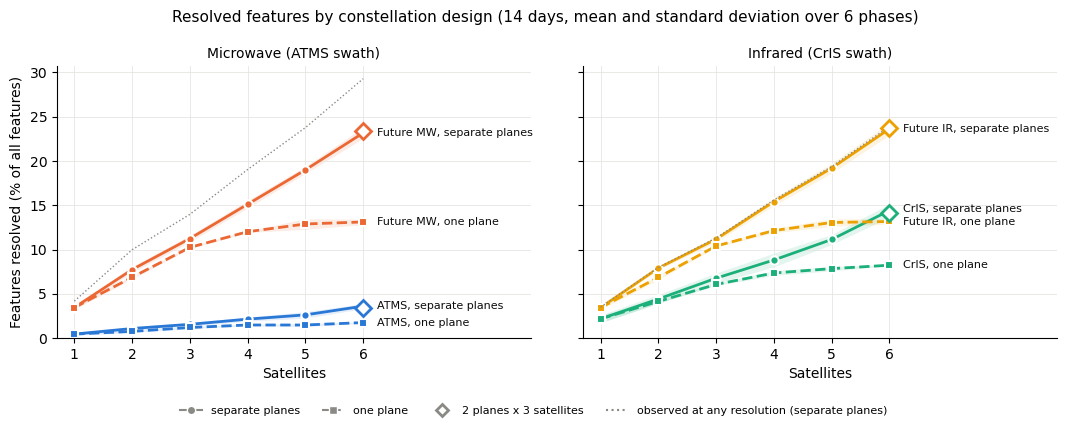

In [13]:
STRATEGIES = {"separate planes": ("-", "o"), "one plane": ("--", "s")}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (title, pair) in zip(
    axes, {"Microwave (ATMS swath)": ("ATMS", "Future MW"), "Infrared (CrIS swath)": ("CrIS", "Future IR")}.items()
):
    ends = []
    for sensor in pair:
        color = SENSOR_COLORS[sensor]
        for strategy, (ls, marker) in STRATEGIES.items():
            selected = trade[(trade.sensor == sensor) & ((trade.planes == 1) if strategy == "one plane" else (trade.per_plane == 1))]
            stats = selected.groupby("satellites")["resolved"].agg(["mean", "std"])
            ax.fill_between(stats.index, stats["mean"] - stats["std"], stats["mean"] + stats["std"], color=color, alpha=0.12, lw=0)
            ax.plot(stats.index, stats["mean"], ls=ls, marker=marker, ms=6, lw=2, color=color, mec="white", mew=1.5)
            ends.append([stats["mean"].iloc[-1], f"{sensor}, {strategy}"])
        two_planes = trade[(trade.sensor == sensor) & (trade.planes == 2) & (trade.per_plane == 3)]["resolved"].mean()
        ax.plot(6, two_planes, marker="D", ms=8, color="white", mec=color, mew=2, zorder=3)
    # direct labels at the line ends, nudged apart so that they do not overlap
    ends.sort()
    for i in range(1, len(ends)):
        ends[i][0] = max(ends[i][0], ends[i - 1][0] + 1.4)
    for y, label in ends:
        ax.annotate(label, (6, y), xytext=(10, 0), textcoords="offset points", va="center", fontsize=8, color=INK)
    # the features observed at any resolution, with separate planes: the most that any sensor can resolve
    observed = trade[(trade.sensor == pair[0]) & (trade.per_plane == 1)].groupby("satellites")["observed"].mean()
    ax.plot(observed.index, observed, color=GRAY, lw=1, ls=":")
    ax.set(title=title, xlabel="Satellites", xticks=range(1, 7), xlim=(0.7, 8.9))
    ax.title.set_fontsize(10)
axes[0].set(ylabel="Features resolved (% of all features)", ylim=(0, None))
legend = [
    plt.Line2D([], [], color=GRAY, ls="-", marker="o", mec="white", label="separate planes"),
    plt.Line2D([], [], color=GRAY, ls="--", marker="s", mec="white", label="one plane"),
    plt.Line2D([], [], color=GRAY, ls="none", marker="D", mfc="white", mew=2, label="2 planes x 3 satellites"),
    plt.Line2D([], [], color=GRAY, ls=":", label="observed at any resolution (separate planes)"),
]
fig.legend(handles=legend, loc="lower center", ncol=4, fontsize=8, frameon=False)
fig.suptitle(
    f"Resolved features by constellation design ({TRADE_DURATION.days} days, mean and standard deviation over {N_DRAWS} phases)",
    fontsize=11,
)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

Over the two weeks, the study region has 1,590 features. The current constellation observes 12% of them in the ATMS swath and 10% in the CrIS swath, and resolves 1% (ATMS), 5% (CrIS), and 10% (either future sensor), somewhat different from the two days above. Evenly spaced in its plane, a constellation of three satellites does slightly better (13% and 11% observed) than the current one, whose satellites are spaced unevenly.

* **Satellites in one plane saturate.** Adding satellites to a single plane observes more features up to about four satellites, and then hardly any more (15 to 16% in the ATMS swath for four to six satellites), because they all observe at the same local times (near 13:30 and 01:30).
* **A second plane gives most of the benefit.** Six satellites in separate planes observe 29% of the features, almost twice as many as six in one plane. Six satellites in two planes (three in each) observe as many (30%): what matters is that the satellites do not duplicate each other's local times, not how many planes there are.
* **Planes and resolution trade against each other.** With heritage sensors, six satellites in separate planes resolve 14% of the features with CrIS, more than six satellites with a future infrared sounder in one plane (13%). Finer resolution pays off fully only with separate planes: a future sounder on six satellites in separate (or two) planes resolves 23 to 24% of the features: nearly all of those observed in the CrIS swath, and four fifths of those in the wider ATMS swath.
* **ATMS is limited by resolution, not sampling.** More planes raise the share resolved by ATMS only from 2% to 4%, because its resolution element is larger than most features wherever they are observed.

The spread between the random phases (the shaded bands) is small compared with these differences. The trade holds the sensors and the altitude fixed; their swaths, altitudes, and resolutions, and orbits other than sun-synchronous ones, are further dimensions of a full trade study.

## Limitations

* **Resolution is geometric.** A sounder's resolution depends on its channels, the retrieval, and the scene. The resolution element here is the larger of the nominal footprint and the sample spacing, scaled by the viewing geometry, without modeling the response (point spread function) of each footprint, the overlap of neighbouring footprints, or where the gaps between the views of CrIS fall on a feature.
* **Infrared sounders do not see through cloud.** Cold cloud tops, the features here, are observed by CrIS at their tops but, unlike microwave sounders, it does not observe the atmosphere beneath. This is not modeled.
* **The future sensors are assumed.** They share the swaths and platforms of ATMS and CrIS and a nominal resolution, and sample in proportion to their footprints, which requires many more views per scan (about 20 times as many for a future infrared sounder as for CrIS). Their own swaths and altitudes are open design variables; the constellation trade varies only the number of satellites and their orbit planes, at the altitude at which the nominal resolutions apply.
* **One realization.** Two days of one nature run year are a small sample (the constellation trade uses two weeks, over which the shares of features that the current constellation resolves differ from those of the two days by up to 3 percentage points). Extend `duration` and `start` to the whole season (mid-June to mid-September) and other years of the Nature Run for statistics.
* **The minimum feature size is a choice.** Features smaller than the Nature Run's effective resolution (`EFFECTIVE_RESOLUTION_KM`, four grid spacings by default) are excluded, about half of the patches of two or more grid cells. The G5NR evaluation gives no single value, and a smaller one would admit features whose structure is set by the model's damping of small scales rather than its physics.
* **Features are snapshots.** A convective system that persists is a feature in each 30-minute frame, and the features of a frame are not tracked from frame to frame.
* **The Nature Run is not reality.** Its convection is simulated and its feature statistics differ from those observed, so the results show the effect of the observing systems on a nature run, which is the point of an OSSE, rather than a forecast of real observations.